Implementation of TLU for Logic Gates

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def step_activation(z):
  if z >= 0:
    return 1
  else:
    return 0

In [4]:
def tlu_logic(inputs,weights,bias):
  inputs = np.array(inputs)
  weights = np.array(weights)
  #z=(w1x1 + w2x2 + ... +wnxn) + b
  z = np.dot(inputs, weights) + bias
  return step_activation(z)

In [5]:
test_inputs = [[0,0], [0,1], [1,0], [1,1]]

AND GATE

In [6]:
#DECISION RULE : x1 + x2 >= 1.5
and_w = [1,1]
and_b = -1.5
print("Testing AND gate Implementation:")
for x in test_inputs:
  prediction = tlu_logic(x, and_w, and_b)
  print(f"Input:  {x} -> Predicted Output: {prediction}")

Testing AND gate Implementation:
Input:  [0, 0] -> Predicted Output: 0
Input:  [0, 1] -> Predicted Output: 0
Input:  [1, 0] -> Predicted Output: 0
Input:  [1, 1] -> Predicted Output: 1


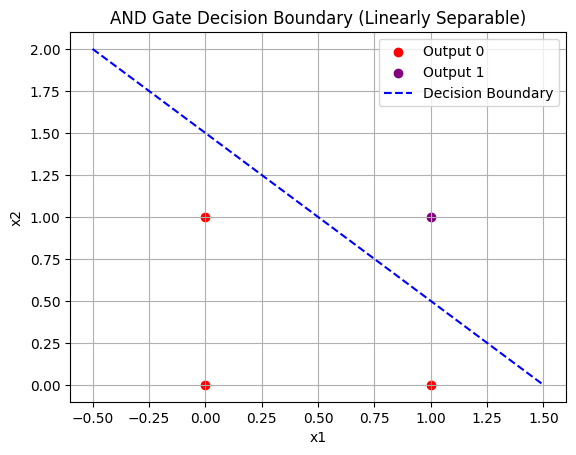

In [7]:
x = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 0, 0, 1])
plt.scatter(x[y==0][:,0], x[y==0][:,1], color = 'red', label = 'Output 0')
plt.scatter(x[y==1][:,0], x[y==1][:,1], color = 'purple', label = 'Output 1')

x1_vals = np.linspace(-0.5, 1.5, 100)
x2_vals = -1 * x1_vals + 1.5

plt.plot(x1_vals, x2_vals, '--b', label = 'Decision Boundary' )
plt.title('AND Gate Decision Boundary (Linearly Separable)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.grid(True)
plt.show()



OR GATE

In [8]:
#Decision Rule: x1+x2 >= 0.5
or_w  = [1,1]
or_b = -0.5
print("Testing OR Gate Implementation:")
for x in test_inputs:
  prediction = tlu_logic(x, or_w, or_b)
  print(f"Input:  {x} -> Predicted Output: {prediction}")




Testing OR Gate Implementation:
Input:  [0, 0] -> Predicted Output: 0
Input:  [0, 1] -> Predicted Output: 1
Input:  [1, 0] -> Predicted Output: 1
Input:  [1, 1] -> Predicted Output: 1


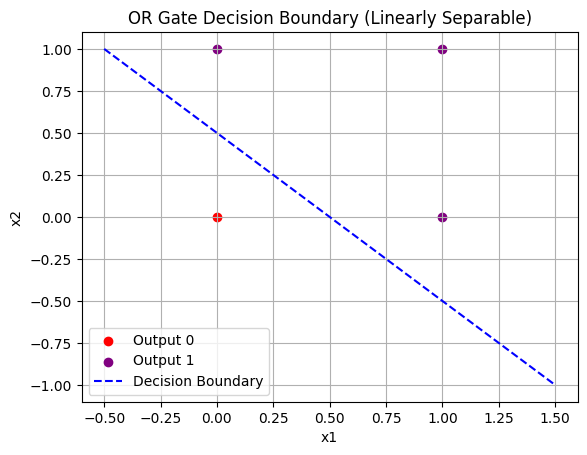

In [9]:
x = np.array([[0,0], [0,1], [1,0], [1,1]])
y_or = np.array([0, 1, 1, 1])
plt.scatter(x[y_or==0][:,0], x[y_or==0][:,1], color = 'red', label = 'Output 0')
plt.scatter(x[y_or==1][:,0], x[y_or==1][:,1], color = 'purple', label = 'Output 1')

x2_vals_or = -1 * x1_vals + 0.5
plt.plot(x1_vals, x2_vals_or, '--b', label = 'Decision Boundary' )
plt.title('OR Gate Decision Boundary (Linearly Separable)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.grid(True)
plt.show()

NAND

In [10]:
#Decision Rule: x1 + x2 < 1.5
nand_w = [-1,-1]
nand_b = 1.5
print("Testing NAND Gate Implementation:")
for x in test_inputs:
  prediction = tlu_logic(x,nand_w,nand_b)
  print(f"Input:  {x} -> Predicted Output: {prediction}")


Testing NAND Gate Implementation:
Input:  [0, 0] -> Predicted Output: 1
Input:  [0, 1] -> Predicted Output: 1
Input:  [1, 0] -> Predicted Output: 1
Input:  [1, 1] -> Predicted Output: 0


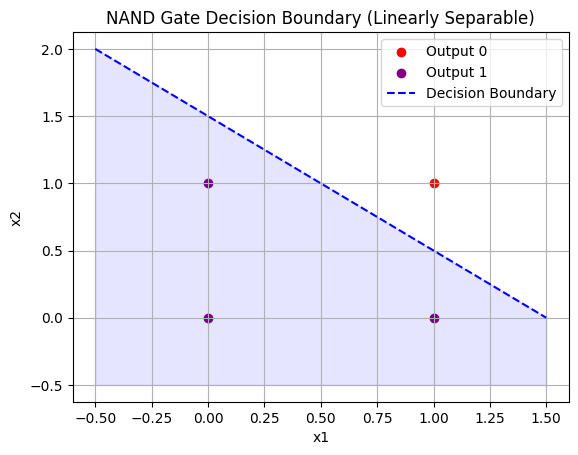

In [11]:
x = np.array([[0,0], [0,1], [1,0], [1,1]])
y_nand = np.array([1, 1, 1, 0])
plt.scatter(x[y_nand==0][:,0], x[y_nand==0][:,1], color = 'red', label = 'Output 0')
plt.scatter(x[y_nand==1][:,0], x[y_nand==1][:,1], color = 'purple', label = 'Output 1')

x2_vals_nand = -1 * x1_vals + 1.5
plt.plot(x1_vals, x2_vals_nand, '--b', label = 'Decision Boundary' )
plt.fill_between(x1_vals,-0.5, x2_vals_nand, color = 'blue', alpha = 0.1)
plt.title('NAND Gate Decision Boundary (Linearly Separable)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.grid(True)
plt.show()


XOR GATE

In [12]:
xor_w = [1,1] #Any weights will fail
xor_b = -0.5
print("Testing XOR Gate Implementation(Expected to Fail):")
for x in test_inputs:
  prediction = tlu_logic(x,xor_w,xor_b)
  print(f"Input: {x} Output: {prediction}")



Testing XOR Gate Implementation(Expected to Fail):
Input: [0, 0] Output: 0
Input: [0, 1] Output: 1
Input: [1, 0] Output: 1
Input: [1, 1] Output: 1


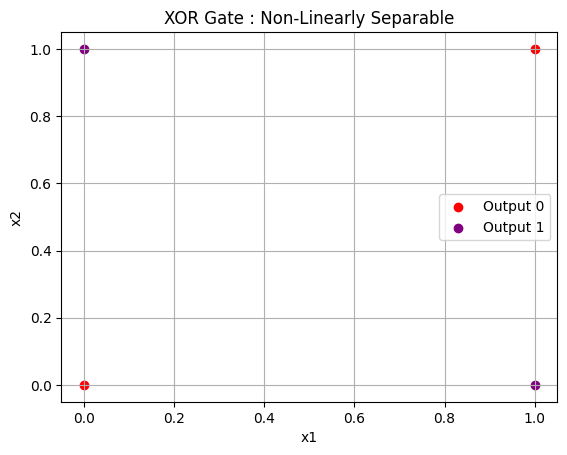

In [13]:
x = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0, 1, 1, 0])
plt.scatter(x[y_xor==0][:,0], x[y_xor==0][:,1], color = 'red', label = 'Output 0')
plt.scatter(x[y_xor==1][:,0], x[y_xor==1][:,1], color = 'purple', label = 'Output 1')
plt.title ("XOR Gate : Non-Linearly Separable")
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.grid(True)
plt.show()

 XOR MLP Output Regions (Illustrative Continuous Grid)

It has one hidden layer with two neurons


*   Neuron 1 -> OR Gate
*   Neuron 2 -> NAND Gate
so both OR and NAND operate in parallel on same inputs

Output layer : AND Gate combines output of OR and NAND Gate



In [14]:
def xor_mlp(inputs):
  h1 = tlu_logic(inputs, or_w, or_b) #OR Gate
  h2 = tlu_logic(inputs, nand_w, nand_b) #NAND Gate
  final_input = [h1,h2]
  return tlu_logic(final_input, and_w, and_b)
print("Final XOR MLP Results:")
for x in test_inputs:
  prediction = xor_mlp(x)
  print(f"Input: {x} -> Predicted XOR Output: {prediction}")


Final XOR MLP Results:
Input: [0, 0] -> Predicted XOR Output: 0
Input: [0, 1] -> Predicted XOR Output: 1
Input: [1, 0] -> Predicted XOR Output: 1
Input: [1, 1] -> Predicted XOR Output: 0


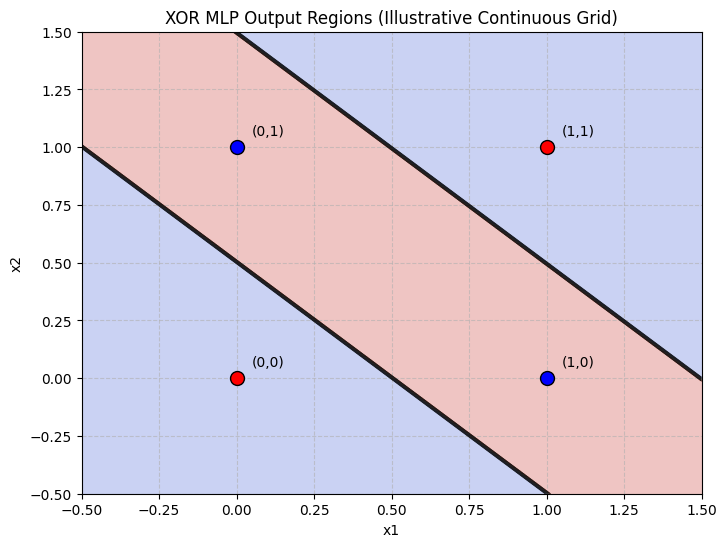

In [15]:
x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5 #set boundaries
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                     np.linspace(y_min, y_max, 100))

# Predict for every point in the grid
Z = np.array([xor_mlp([x1, x2]) for x1, x2 in zip(xx.ravel(), yy.ravel())])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

# Plot the decision boundary
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.contour(xx, yy, Z, colors='k', linewidths=0.5)

# Plot the 4 XOR points
for i, x in enumerate(test_inputs):
    color = 'red' if xor_mlp(x) == 0 else 'blue'
    plt.scatter(x[0], x[1], c=color, s=100, edgecolors='k', zorder=3)
    plt.text(x[0]+0.05, x[1]+0.05, f"({x[0]},{x[1]})")
# Illustrative visualization on a continuous-valued grid.
# Binary XOR correctness is verified separately using the four truth-table inputs.
plt.title("XOR MLP Output Regions (Illustrative Continuous Grid)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Bipolar Coordinates

In [16]:
def bipolar_activation(z):
  return 1 if z >= 0 else -1
def test_bipolar_gate(w1, w2, bias, gate_name):
  bipolar_inputs = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]])
  print(f"--- Testing Bipolar {gate_name} Gate ---")
  for x in bipolar_inputs:
    x1, x2 = x[0], x[1]
    z = (w1 * x1) + (w2 * x2) + bias
    output = bipolar_activation(z)
    print(f"Input: [{x1:2}, {x2:2}] -> Net Input (z): {z:4.1f} -> Predicted Output: {output:2}")
  print()
test_bipolar_gate(w1=1,  w2=1,  bias=-1.5, gate_name="AND")
test_bipolar_gate(w1=1,  w2=1,  bias=+0.5, gate_name="OR")
test_bipolar_gate(w1=-1, w2=-1, bias=1.5,  gate_name="NAND")

--- Testing Bipolar AND Gate ---
Input: [-1, -1] -> Net Input (z): -3.5 -> Predicted Output: -1
Input: [-1,  1] -> Net Input (z): -1.5 -> Predicted Output: -1
Input: [ 1, -1] -> Net Input (z): -1.5 -> Predicted Output: -1
Input: [ 1,  1] -> Net Input (z):  0.5 -> Predicted Output:  1

--- Testing Bipolar OR Gate ---
Input: [-1, -1] -> Net Input (z): -1.5 -> Predicted Output: -1
Input: [-1,  1] -> Net Input (z):  0.5 -> Predicted Output:  1
Input: [ 1, -1] -> Net Input (z):  0.5 -> Predicted Output:  1
Input: [ 1,  1] -> Net Input (z):  2.5 -> Predicted Output:  1

--- Testing Bipolar NAND Gate ---
Input: [-1, -1] -> Net Input (z):  3.5 -> Predicted Output:  1
Input: [-1,  1] -> Net Input (z):  1.5 -> Predicted Output:  1
Input: [ 1, -1] -> Net Input (z):  1.5 -> Predicted Output:  1
Input: [ 1,  1] -> Net Input (z): -0.5 -> Predicted Output: -1



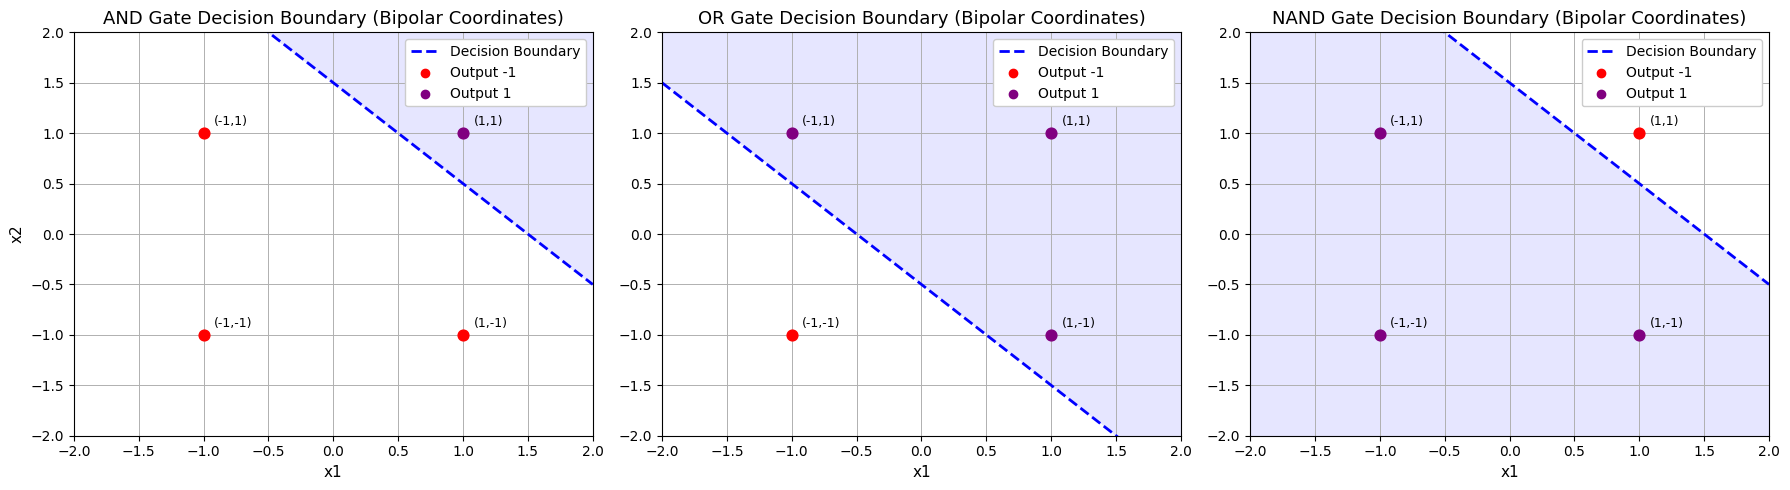

In [18]:
gates_config = {
    "AND Gate":  {"w1": 1,  "w2": 1,  "bias": -1.5, "b_range": [-1.5, 2.0]},
    "OR Gate":   {"w1": 1,  "w2": 1,  "bias": 0.5,  "b_range": [-1.5, 2.0]},
    "NAND Gate": {"w1": -1, "w2": -1, "bias": 1.5, "b_range": [0, 2.0]}
}

# Setup 3 side-by-side subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# continuous grid background for region visualization
xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))

for idx, (name, cfg) in enumerate(gates_config.items()):
    ax = axes[idx]
    w1, w2, b = cfg["w1"], cfg["w2"], cfg["bias"]

    # Calculate explicit boundary line equation: w1*x1 + w2*x2 + b = 0
    x1_space = np.linspace(-2, 2, 100)
    x2_line = (-w1 * x1_space - b) / w2

    # Compute output values over background grid
    zz = (w1 * xx) + (w2 * yy) + b
    activated_grid = np.where(zz >= 0, 1, -1)

    # Shading: Light purple/blue for output +1, white for output -1
    ax.contourf(xx, yy, activated_grid, levels=[-1.5, 0, 1.5], colors=['#ffffff', '#e6e6ff'], alpha=1.0)

    # Plot the explicit mathematical boundary hyperplane
    ax.plot(x1_space, x2_line, 'b--', linewidth=2, label='Decision Boundary')

    ax.scatter([], [], color='red', label='Output -1') # Using -1 since outputs are bipolar
    ax.scatter([], [], color='purple', label='Output 1')

    # Plot the 4 classic bipolar coordinate points
    for x1, x2 in [(-1, -1), (-1, 1), (1, -1), (1, 1)]:
        net = (w1 * x1) + (w2 * x2) + b
        out = 1 if net >= 0 else -1

        # Color : Purple for high (1), Red for low (-1)
        dot_color = 'purple' if out == 1 else 'red'
        ax.scatter(x1, x2, color=dot_color, s=60, zorder=5)
        ax.text(x1 + 0.08, x2 + 0.08, f"({x1},{x2})", fontsize=9, zorder=6)

    # Subplot styling
    ax.set_title(f"{name} Decision Boundary (Bipolar Coordinates)", fontsize=13)
    ax.set_xlabel('x1', fontsize=11)
    ax.set_ylabel('x2', fontsize=11) if idx == 0 else None # Only left axis needs y-label for clean spacing
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.grid(True, which='both', linestyle='-', linewidth=0.7)
    ax.legend(loc='upper right', framealpha=1.0)

plt.tight_layout()
plt.show()
